`[Cell 1]`

## MODMA3: CNN + channel attention (MDD vs healthy control)

In [ ]:
# [Cell 2]
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    f1_score,
    roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense,
    Dropout, Multiply,
    Conv2D, MaxPooling2D, GlobalAveragePooling2D, Reshape
)
from tensorflow.keras.optimizers import Adam


In [ ]:
# [Cell 3]
# Local dataset location (relative to this notebook's folder)
manavrajpurohit_modma_dataset_path = 'MODMA3'


In [ ]:
# [Cell 4]
# CELL-2: Paths & Global Settings


# Update BASE_PATH and INFO_CSV to use the downloaded dataset path
BASE_PATH = os.path.join(manavrajpurohit_modma_dataset_path, "EEG_128channels_ERP_lanzhou_2015", "EEG_128channels_ERP_lanzhou_2015")
INFO_CSV = os.path.join(manavrajpurohit_modma_dataset_path, "ERP_MDD_HC_data.csv")

RANDOM_SEED = 42
EPOCHS_PER_SUBJECT = 250   # 🔥 KEY for realistic results
BATCH_SIZE = 64
EPOCHS = 10

np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)


In [ ]:
# [Cell 5]
# CELL-3: Load ALL Subjects (FIXED & SAFE)

mdd_files = []
healthy_files = []

df_info = pd.read_csv(INFO_CSV)

subject_type = {}
for _, row in df_info.iterrows():
    sid = str(row["subject id"]).zfill(8)
    subject_type[sid] = row["type"]

for file in os.listdir(BASE_PATH):
    if not file.endswith(".raw"):
        continue

    subject_id = file.split(" ")[0]
    subject_id = subject_id.replace("erp", "").replace("_", "")

    if subject_id in subject_type:
        full_path = f"{BASE_PATH}/{file}"
        if subject_type[subject_id] == "MDD":
            mdd_files.append(full_path)
        else:
            healthy_files.append(full_path)

print("MDD subjects:", len(mdd_files))
print("Healthy subjects:", len(healthy_files))


MDD subjects: 23
Healthy subjects: 27


In [ ]:
# [Cell 6]
# CELL-4: EEG Preprocessing Function

def preprocess_eeg(file_path, max_epochs=250):
    raw = mne.io.read_raw_egi(file_path, preload=False, verbose=False)
    raw.pick_types(eeg=True)
    raw.load_data()

    raw.filter(0.5, 40, fir_design='firwin')
    raw.resample(128)

    events, _ = mne.events_from_annotations(raw)
    if len(events) == 0:
        return None

    # random subset of events, kept in time order (mne.Epochs expects sorted events)
    keep = np.sort(np.random.choice(len(events), min(len(events), max_epochs), replace=False))
    events = events[keep]

    epochs = mne.Epochs(
        raw,
        events,
        tmin=0.0,
        tmax=1.0,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        event_repeated="drop",
        verbose=False
    )

    return epochs


In [ ]:
# [Cell 7]
# CELL-5: Process Subject Groups (RAM-SAFE)

def process_group(file_list, label):
    X, y, g = [], [], []

    for f in file_list:
        ep = preprocess_eeg(f, EPOCHS_PER_SUBJECT)
        if ep is None:
            continue

        data = ep.get_data()   # (epochs, channels, time)
        X.append(data)
        y.extend([label] * data.shape[0])
        g.extend([os.path.basename(f).split(" ")[0]] * data.shape[0])  # subject id per epoch

    X = np.vstack(X)
    y = np.array(y)

    return X, y, np.array(g)


In [ ]:
# [Cell 8]
#CELL-6: Load FULL Dataset (Balanced)

X_mdd, y_mdd, g_mdd = process_group(mdd_files, label=1)
X_hc, y_hc, g_hc = process_group(healthy_files, label=0)

X = np.concatenate([X_mdd, X_hc])
y = np.concatenate([y_mdd, y_hc])
groups = np.concatenate([g_mdd, g_hc])

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)


NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Reading 0 ... 203614  =      0.000 ...   814.456 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (6.604 s)

Used Annotations descriptions: ['CELL', 'SESS', 'TRSP', 'bgin', 'epoc', 'fcue', 'fdot', 'ffix', 'fisi', 'fwrp', 'hcue', 'hdot', 'hfix', 'hisi', 'hwrp', 'resp', 'scue', 'sdot', 'sfix', 'sisi', 'swrp']


/tmp/ipykernel_1975/1616314959.py:18: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Reading 0 ... 201150  =      0.000 ...   804.600 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (6.604 s)

Used Annotations descriptions: ['CELL', 'SESS', 'TRSP', 'bgin', 'epoc', 'fcue', 'fdot', 'ffix', 'fisi', 'fwrp', 'hcue', 'hdot', 'hfix', 'hisi', 'hwrp', 'resp', 'scue', 'sdot', 'sfix', 'sisi', 'swrp']


/tmp/ipykernel_1975/1616314959.py:18: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Reading 0 ... 211052  =      0.000 ...   844.208 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (6.604 s)

Used Annotations descriptions: ['CELL', 'SESS', 'TRSP', 'bgin', 'epoc', 'fcue', 'fdot', 'ffix', 'fisi', 'fwrp', 'hcue', 'hdot', 'hfix', 'hisi', 'hwrp', 'resp', 'scue', 'sdot', 'sfix', 'sisi', 'swrp']


/tmp/ipykernel_1975/1616314959.py:18: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


... (77 outputs left out)

/tmp/ipykernel_1975/1616314959.py:18: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Reading 0 ... 212138  =      0.000 ...   848.552 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (6.604 s)

Used Annotations descriptions: ['CELL', 'D127', 'DI18', 'DI26', 'DI27', 'SESS', 'TRSP', 'bgin', 'epoc', 'fcue', 'fdot', 'ffix', 'fisi', 'fwrp', 'hcue', 'hdot', 'hfix', 'hisi', 'hwrp', 'resp', 'scue', 'sdot', 'sfix', 'sisi', 'swrp']


/tmp/ipykernel_1975/1616314959.py:18: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


Final X shape: (12477, 129, 129)
Final y shape: (12477,)


In [ ]:
# [Cell 9]
# CELL-7 — TRAIN / TEST SPLIT

# Split by SUBJECT so no subject's epochs appear in both train and test
subj_ids = np.unique(groups)
subj_y = np.array([y[groups == s][0] for s in subj_ids])
train_subj, test_subj = train_test_split(
    subj_ids, test_size=0.2, random_state=42, stratify=subj_y
)
train_mask = np.isin(groups, train_subj)
perm = np.random.RandomState(42).permutation(train_mask.sum())  # shuffle: keras validation_split takes the last 20%
X_train, y_train = X[train_mask][perm], y[train_mask][perm]
X_test, y_test = X[~train_mask], y[~train_mask]
subject_ids_test = groups[~train_mask]

# Add channel dimension
X_train = X_train[..., np.newaxis]
X_test  = X_test[..., np.newaxis]

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)


Train: (9981, 129, 129, 1) (9981,)
Test : (2496, 129, 129, 1) (2496,)


In [ ]:
# [Cell 10]
# CELL-7.5 (NEW) — EEG NORMALIZATION

# Normalize each sample (z-score per epoch)
def normalize_eeg(X):
    mean = np.mean(X, axis=(1,2), keepdims=True)
    std  = np.std(X, axis=(1,2), keepdims=True) + 1e-6
    return (X - mean) / std

X_train = normalize_eeg(X_train)
X_test  = normalize_eeg(X_test)

print("Normalization done")


Normalization done


In [ ]:
# [Cell 11]
# CELL-8 — CHANNEL ATTENTION BLOCK (SE BLOCK)
# unique contribution

def channel_attention(inputs, ratio=8):
    channel = inputs.shape[-1]

    shared_dense_1 = Dense(channel // ratio, activation='relu')
    shared_dense_2 = Dense(channel, activation='sigmoid')

    avg_pool = GlobalAveragePooling1D()(inputs)
    avg_pool = shared_dense_1(avg_pool)
    avg_pool = shared_dense_2(avg_pool)

    avg_pool = tf.expand_dims(avg_pool, 1)
    return Multiply()([inputs, avg_pool])


In [ ]:
# [Cell 12]
# CELL-8.5 (NEW) — CLASS WEIGHTS


class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {
    0: class_weights[0],
    1: class_weights[1]
}

print(class_weight_dict)


{0: np.float64(0.9255378338278932), 1: np.float64(1.0874918282850294)}


In [ ]:
# [Cell 13]
# CELL-9 — CNN + Channel Attention MODEL



def channel_attention_2d(inputs, ratio=8):
    channel = inputs.shape[-1]

    x = GlobalAveragePooling2D()(inputs)
    x = Dense(channel // ratio, activation='relu')(x)
    x = Dense(channel, activation='sigmoid')(x)

    x = Reshape((1, 1, channel))(x)
    return Multiply()([inputs, x])

inputs = Input(shape=X_train.shape[1:])

x = Conv2D(32, (3,3), activation='relu', padding='same')(inputs)
x = MaxPooling2D((2,2))(x)

x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = MaxPooling2D((2,2))(x)

x = channel_attention_2d(x)

x = GlobalAveragePooling2D()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=Adam(learning_rate=3e-4),  # was 1e-4
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 129, 129,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 129, 129,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │        520 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │        576 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 64)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 32, 32,    │          0 │ max_pooling2d_1[… │
│                     │ 64)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ multiply[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      4,160 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,137 (94.29 KB)

 Trainable params: 24,137 (94.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# [Cell 14]
# CELL-10 — TRAIN MODEL (SAFE SETTINGS)

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weight_dict,
    verbose=1
)


Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 233s 921ms/step - accuracy: 0.5243 - loss: 0.6928 - val_accuracy: 0.5093 - val_loss: 0.6919
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 256s 898ms/step - accuracy: 0.5614 - loss: 0.6852 - val_accuracy: 0.4892 - val_loss: 0.7051
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 215s 860ms/step - accuracy: 0.5916 - loss: 0.6709 - val_accuracy: 0.5148 - val_loss: 0.7040
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 266s 877ms/step - accuracy: 0.6221 - loss: 0.6559 - val_accuracy: 0.5568 - val_loss: 0.6847
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 216s 866ms/step - accuracy: 0.6349 - loss: 0.6462 - val_accuracy: 0.5648 - val_loss: 0.6829
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 221s 883ms/step - accuracy: 0.6442 - loss: 0.6391 - val_accuracy: 0.5904 - val_loss: 0.6675
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 224s 895ms/step - accuracy: 0.6541 - loss: 0.6323 - val_accuracy: 0.6104 - val_loss: 0.6506
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 262s 898ms/step - accuracy: 0.6577 -

In [ ]:
# [Cell 15]
# CELL-11 — GET EPOCH-LEVEL PREDICTIONS (SAFE)

y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

print("Epoch-level Accuracy:",
      accuracy_score(y_test, y_pred))
print("Epoch-level F1:",
      f1_score(y_test, y_pred))


78/78 ━━━━━━━━━━━━━━━━━━━━ 18s 224ms/step
Epoch-level Accuracy: 0.6963141025641025
Epoch-level F1: 0.6965572457966374


In [ ]:
# [Cell 16]
# CELL-12 — SUBJECT-LEVEL AGGREGATION (CORE CONTRIBUTION)

# CELL-12A — BUILD SUBJECT IDS (SAFE ASSUMPTION)

# subject_ids_test comes from the subject-level split above


In [ ]:
# [Cell 17]
# CELL-12B — SUBJECT-LEVEL VOTING


df_pred = pd.DataFrame({
    "subject": subject_ids_test,
    "y_true": y_test,
    "y_prob": y_pred_prob
})

# Aggregate per subject
df_subject = df_pred.groupby("subject").agg(
    y_true=("y_true", "mean"),
    y_prob=("y_prob", "mean")
).reset_index()

# 🔴 IMPORTANT FIXES
df_subject["y_true_bin"] = (df_subject["y_true"] >= 0.5).astype(int)
df_subject["y_pred"] = (df_subject["y_prob"] >= 0.5).astype(int)

print("Subject-level Accuracy:",
      accuracy_score(df_subject["y_true_bin"], df_subject["y_pred"]))

print("Subject-level F1:",
      f1_score(df_subject["y_true_bin"], df_subject["y_pred"]))

print("Subject-level AUC:",
      roc_auc_score(df_subject["y_true_bin"], df_subject["y_prob"]))


Subject-level Accuracy: 0.5714285714285714
Subject-level F1: 0.6
Subject-level AUC: 0.7830721003134796


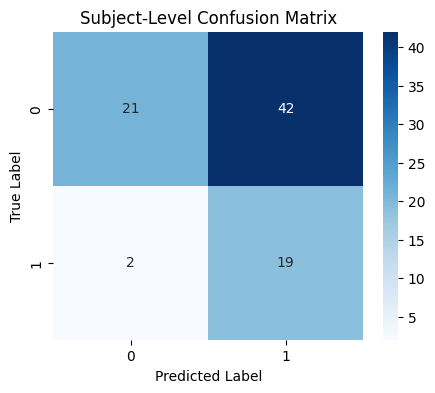

In [ ]:
# [Cell 18]
# CELL-13 — CONFUSION MATRIX (SUBJECT-LEVEL FIGURE)


cm = confusion_matrix(
    df_subject["y_true"].round(),
    df_subject["y_pred"]
)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Subject-Level Confusion Matrix")
plt.show()


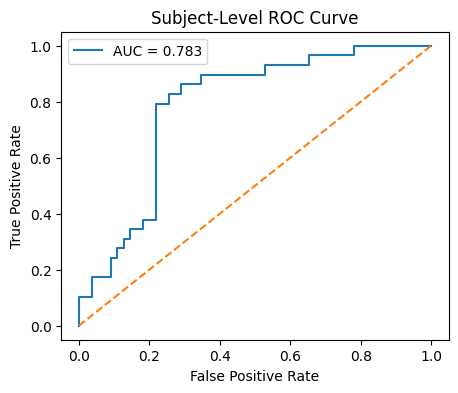

In [ ]:
# [Cell 19]
# CELL-14 — ROC CURVE (SUBJECT-LEVEL)


fpr, tpr, _ = roc_curve(
    df_subject["y_true_bin"],
    df_subject["y_prob"]  # predicted probabilities
)

plt.figure(figsize=(5,4))
plt.plot(fpr, tpr,
         label="AUC = %.3f" %
         roc_auc_score(df_subject["y_true_bin"], df_subject["y_prob"]))
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Subject-Level ROC Curve")
plt.legend()
plt.show()


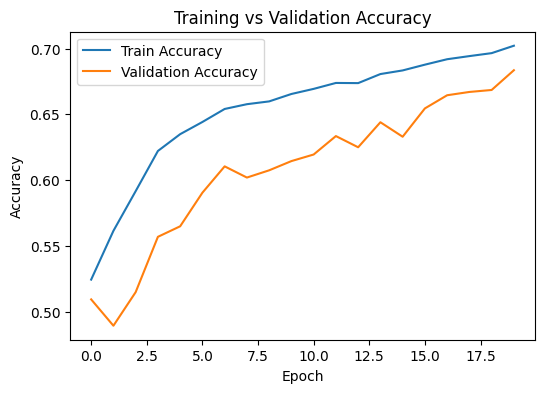

In [ ]:
# [Cell 20]
# CELL-15 — TRAINING CURVES (FOR SLIDES)

plt.figure(figsize=(6,4))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()


In [ ]:
# [Cell 21]
# CELL-16 — FINAL METRICS SUMMARY


print("========== FINAL RESULTS ==========")
print("Epoch-level Accuracy:",
      accuracy_score(y_test, y_pred))

print("Subject-level Accuracy:",
      accuracy_score(df_subject["y_true_bin"], df_subject["y_pred"]))

print("Subject-level F1:",
      f1_score(df_subject["y_true_bin"], df_subject["y_pred"]))

print("Subject-level AUC:",
      roc_auc_score(df_subject["y_true_bin"], df_subject["y_prob"]))


========== FINAL RESULTS ==========
Epoch-level Accuracy: 0.6963141025641025
Subject-level Accuracy: 0.5714285714285714
Subject-level F1: 0.6
Subject-level AUC: 0.7830721003134796
